# COPD Model Training

**Dataset:** NHANES  
**Task:** Participant-level tabular baseline

COPD label must be reviewed and derived from the approved spirometry definition. Exclude label-defining spirometry values from predictors.

## Stage 1: Setup

In [ ]:
# ------------------ Stage 1: Setup ------------------

%pip install -q pandas numpy matplotlib seaborn scikit-learn scipy xgboost shap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

## Stage 2: Load Dataset

In [ ]:
# Stage 2: Load Dataset

from google.colab import files
import pandas as pd

uploaded = files.upload()

datasets = {}

for name in uploaded:
    if name.lower().endswith(".xpt"):
        datasets[name.rsplit(".", 1)[0]] = pd.read_sas(
            name, format="xport"
        )

print("Loaded datasets:")

for name, data in datasets.items():
    print(name, data.shape)

Saving DEMO_G.XPT to DEMO_G.XPT
Saving MCQ_G.XPT to MCQ_G.XPT
Saving OCQ_G.XPT to OCQ_G.XPT
Saving RDQ_G.XPT to RDQ_G.XPT
Saving SMQ_G.XPT to SMQ_G.XPT
Saving SPX_G.XPT to SPX_G.XPT
Loaded datasets:
DEMO_G (9756, 48)
MCQ_G (9364, 92)
OCQ_G (6175, 22)
RDQ_G (9364, 15)
SMQ_G (6790, 30)
SPX_G (7495, 51)


## Stage 3: Inspect Dataset Columns

In [ ]:
# ------------------ Stage 3: Data Inspection ------------------

for name, data in datasets.items():
    print(f"\n{name}")
    print(data.columns.tolist())


DEMO_G
['SEQN', 'SDDSRVYR', 'RIDSTATR', 'RIAGENDR', 'RIDAGEYR', 'RIDAGEMN', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'RIDEXAGY', 'RIDEXAGM', 'DMQMILIZ', 'DMQADFC', 'DMDBORN4', 'DMDCITZN', 'DMDYRSUS', 'DMDEDUC3', 'DMDEDUC2', 'DMDMARTL', 'RIDEXPRG', 'SIALANG', 'SIAPROXY', 'SIAINTRP', 'FIALANG', 'FIAPROXY', 'FIAINTRP', 'MIALANG', 'MIAPROXY', 'MIAINTRP', 'AIALANGA', 'WTINT2YR', 'WTMEC2YR', 'SDMVPSU', 'SDMVSTRA', 'INDHHIN2', 'INDFMIN2', 'INDFMPIR', 'DMDHHSIZ', 'DMDFMSIZ', 'DMDHHSZA', 'DMDHHSZB', 'DMDHHSZE', 'DMDHRGND', 'DMDHRAGE', 'DMDHRBR4', 'DMDHREDU', 'DMDHRMAR', 'DMDHSEDU']

MCQ_G
['SEQN', 'MCQ010', 'MCQ025', 'MCQ035', 'MCQ040', 'MCQ050', 'MCQ051', 'MCQ053', 'MCQ070', 'MCQ075', 'MCQ080', 'MCQ082', 'MCQ084', 'MCQ086', 'MCQ092', 'MCD093', 'MCQ140', 'MCQ149', 'MCQ160A', 'MCQ180A', 'MCQ195', 'MCQ160N', 'MCQ180N', 'MCQ160B', 'MCQ180B', 'MCQ160C', 'MCQ180C', 'MCQ160D', 'MCQ180D', 'MCQ160E', 'MCQ180E', 'MCQ160F', 'MCQ180F', 'MCQ160G', 'MCQ180G', 'MCQ160M', 'MCQ170M', 'MCQ180M', 'MCQ160K', 'MCQ170K

In [ ]:
# Inspect Spirometry Measurements

spx = datasets["SPX_G"]

cols = [
    "SEQN", "SPXNSTAT", "SPXNFVC", "SPXNFEV1",
    "SPXNQFVC", "SPXNQFV1",
    "SPXBSTAT", "SPXBFVC", "SPXBFEV1"
]

print(spx[cols].head(10))

      SEQN  SPXNSTAT  SPXNFVC  SPXNFEV1 SPXNQFVC SPXNQFV1  SPXBSTAT  SPXBFVC  \
0  62161.0       1.0   4536.0    4265.0     b'C'     b'B'       NaN      NaN   
1  62163.0       1.0   3667.0    3563.0     b'B'     b'A'       NaN      NaN   
2  62164.0       1.0   4566.0    3397.0     b'A'     b'A'       NaN      NaN   
3  62165.0       1.0   2531.0    2207.0     b'A'     b'A'       NaN      NaN   
4  62166.0       1.0   1822.0    1715.0     b'A'     b'A'       NaN      NaN   
5  62168.0       1.0   1924.0    1542.0     b'B'     b'B'       NaN      NaN   
6  62169.0       1.0   4278.0    3927.0     b'A'     b'A'       NaN      NaN   
7  62170.0       1.0   4296.0    3775.0     b'C'     b'B'       NaN      NaN   
8  62171.0       1.0   4177.0    3842.0     b'A'     b'A'       NaN      NaN   
9  62172.0       2.0   3206.0    2589.0     b'D'     b'D'       NaN      NaN   

   SPXBFEV1  
0       NaN  
1       NaN  
2       NaN  
3       NaN  
4       NaN  
5       NaN  
6       NaN  
7      

In [ ]:
# Check Spirometry Quality

for col in ["SPXNSTAT", "SPXNQFVC", "SPXNQFV1",
            "SPXBSTAT", "SPXBQFVC", "SPXBQFV1"]:

    print(f"\n{col}")
    print(spx[col].value_counts(dropna=False))


SPXNSTAT
SPXNSTAT
1.0    6344
3.0     437
4.0     363
2.0     351
Name: count, dtype: int64

SPXNQFVC
SPXNQFVC
b'A'    4104
b'B'    1562
b''      799
b'C'     718
b'D'     249
b'F'      63
Name: count, dtype: int64

SPXNQFV1
SPXNQFV1
b'A'    4267
b'B'    1618
b''      799
b'C'     547
b'D'     216
b'F'      48
Name: count, dtype: int64

SPXBSTAT
SPXBSTAT
NaN    6653
1.0     456
3.0     218
4.0     167
2.0       1
Name: count, dtype: int64

SPXBQFVC
SPXBQFVC
b''     7038
b'A'     321
b'B'     107
b'C'      28
b'D'       1
Name: count, dtype: int64

SPXBQFV1
SPXBQFV1
b''     7038
b'A'     334
b'B'      90
b'C'      33
Name: count, dtype: int64


In [ ]:
# Inspect Bronchodilator Selection

spx = datasets["SPX_G"]

for col in ["SPDBRONC", "SPXNCMT", "SPXBCMT",
            "SPXNQEFF", "SPXBQEFF"]:

    print(f"\n{col}")
    print(spx[col].value_counts(dropna=False))


SPDBRONC
SPDBRONC
2.0    5853
1.0     842
NaN     800
Name: count, dtype: int64

SPXNCMT
SPXNCMT
NaN      6963
56.0      225
99.0       81
2.0        70
4.0        34
84.0       33
122.0      23
5.0        21
3.0        15
7.0        14
51.0       11
6.0         3
72.0        1
14.0        1
Name: count, dtype: int64

SPXBCMT
SPXBCMT
NaN     7291
2.0      115
99.0      70
51.0       7
3.0        4
5.0        3
27.0       2
7.0        2
4.0        1
Name: count, dtype: int64

SPXNQEFF
SPXNQEFF
b'A'    6116
b''      809
b'C'     347
b'B'     223
Name: count, dtype: int64

SPXBQEFF
SPXBQEFF
b''     7038
b'A'     444
b'C'      10
b'B'       3
Name: count, dtype: int64


In [ ]:
# Inspect Age and COPD-Related History

demo = datasets["DEMO_G"]
mcq = datasets["MCQ_G"]

print("Age distribution:")
print(demo["RIDAGEYR"].describe())

print("\nEmphysema history:")
print(mcq["MCQ160G"].value_counts(dropna=False))

print("\nChronic bronchitis history:")
print(mcq["MCQ160K"].value_counts(dropna=False))

Age distribution:
count    9.756000e+03
mean     3.140262e+01
std      2.457899e+01
min      5.397605e-79
25%      9.000000e+00
50%      2.600000e+01
75%      5.200000e+01
max      8.000000e+01
Name: RIDAGEYR, dtype: float64

Emphysema history:
MCQ160G
2.0    5450
NaN    3805
1.0     100
9.0       8
7.0       1
Name: count, dtype: int64

Chronic bronchitis history:
MCQ160K
2.0    5253
NaN    3805
1.0     297
9.0       8
7.0       1
Name: count, dtype: int64


In [ ]:
# Inspect Spirometry Quality

for col in ["SPXNQEFF", "SPXNQFVC", "SPXNQFV1"]:
    print(f"\n{col}")
    print(spx[col].value_counts(dropna=False))


SPXNQEFF
SPXNQEFF
b'A'    6116
b''      809
b'C'     347
b'B'     223
Name: count, dtype: int64

SPXNQFVC
SPXNQFVC
b'A'    4104
b'B'    1562
b''      799
b'C'     718
b'D'     249
b'F'      63
Name: count, dtype: int64

SPXNQFV1
SPXNQFV1
b'A'    4267
b'B'    1618
b''      799
b'C'     547
b'D'     216
b'F'      48
Name: count, dtype: int64


In [ ]:
# Inspect COPD-Related Medical History

mcq = datasets["MCQ_G"]

for col in ["MCQ160G", "MCQ160K"]:
    print(f"\n{col}")
    print(mcq[col].value_counts(dropna=False))


MCQ160G
MCQ160G
2.0    5450
NaN    3805
1.0     100
9.0       8
7.0       1
Name: count, dtype: int64

MCQ160K
MCQ160K
2.0    5253
NaN    3805
1.0     297
9.0       8
7.0       1
Name: count, dtype: int64


In [ ]:
# Inspect Spirometry Age Eligibility

demo = datasets["DEMO_G"]

print("Participants aged 20 and above:")
print((demo["RIDAGEYR"] >= 20).sum())

print("\nParticipants aged 40 and above:")
print((demo["RIDAGEYR"] >= 40).sum())

Participants aged 20 and above:
5560

Participants aged 40 and above:
3603


In [ ]:
# Inspect Eligible COPD Participants

demo = datasets["DEMO_G"]
spx = datasets["SPX_G"]

temp = pd.merge(
    demo[["SEQN", "RIDAGEYR", "RIAGENDR", "RIDRETH1"]],
    spx,
    on="SEQN",
    how="inner"
)

eligible = temp[temp["RIDAGEYR"] >= 40].copy()

print("Total merged participants:", len(temp))
print("Participants aged 40+:", len(eligible))

print("\nBaseline spirometry status:")
print(eligible["SPXNSTAT"].value_counts(dropna=False))

print("\nBronchodilator selection:")
print(eligible["SPDBRONC"].value_counts(dropna=False))

print("\nPost-bronchodilator status:")
print(eligible["SPXBSTAT"].value_counts(dropna=False))

Total merged participants: 7495
Participants aged 40+: 3115

Baseline spirometry status:
SPXNSTAT
1.0    2525
4.0     247
3.0     210
2.0     133
Name: count, dtype: int64

Bronchodilator selection:
SPDBRONC
2.0    2189
1.0     469
NaN     457
Name: count, dtype: int64

Post-bronchodilator status:
SPXBSTAT
NaN    2646
1.0     195
3.0     139
4.0     135
Name: count, dtype: int64


In [ ]:
# Inspect Valid Baseline Spirometry

eligible["FEV1_FVC"] = (
    eligible["SPXNFEV1"] / eligible["SPXNFVC"]
)

valid = eligible[
    (eligible["SPXNSTAT"] == 1) &
    (eligible["SPXNQFV1"].isin([b"A", b"B"])) &
    (eligible["SPXNQFVC"].isin([b"A", b"B"])) &
    (eligible["SPXNFVC"] > 0)
].copy()

print("Valid participants:", len(valid))

print("\nFEV1/FVC ratio:")
print(valid["FEV1_FVC"].describe())

print("\nParticipants below 0.70:")
print((valid["FEV1_FVC"] < 0.70).sum())

print("\nParticipants at or above 0.70:")
print((valid["FEV1_FVC"] >= 0.70).sum())

Valid participants: 2213

FEV1/FVC ratio:
count    2213.000000
mean        0.762295
std         0.078048
min         0.313041
25%         0.724293
50%         0.773065
75%         0.816257
max         0.967408
Name: FEV1_FVC, dtype: float64

Participants below 0.70:
385

Participants at or above 0.70:
1828


In [ ]:
# Inspect Post-Bronchodilator Spirometry

post_valid = eligible[
    (eligible["SPXBSTAT"] == 1) &
    (eligible["SPXBQFV1"].isin([b"A", b"B"])) &
    (eligible["SPXBQFVC"].isin([b"A", b"B"])) &
    (eligible["SPXBFVC"] > 0)
].copy()

post_valid["POST_FEV1_FVC"] = (
    post_valid["SPXBFEV1"] / post_valid["SPXBFVC"]
)

print("Valid post-bronchodilator participants:", len(post_valid))

print("\nPost-bronchodilator ratio:")
print(post_valid["POST_FEV1_FVC"].describe())

print("\nRatio below 0.70:")
print((post_valid["POST_FEV1_FVC"] < 0.70).sum())

Valid post-bronchodilator participants: 182

Post-bronchodilator ratio:
count    182.000000
mean       0.681869
std        0.065260
min        0.380489
25%        0.653965
50%        0.695981
75%        0.725391
max        0.798928
Name: POST_FEV1_FVC, dtype: float64

Ratio below 0.70:
97


## Stage 4: Merge NHANES Datasets

In [ ]:
# Create baseline obstruction target

valid["baseline_obstruction_flag"] = (
    valid["FEV1_FVC"] < 0.70
).astype(int)

# Start with eligible spirometry participants
copd_data = valid.copy()

# Merge remaining datasets using participant ID
for name in ["SMQ_G", "MCQ_G", "RDQ_G", "OCQ_G"]:
    copd_data = copd_data.merge(
        datasets[name],
        on="SEQN",
        how="left"
    )

print("Merged dataset shape:", copd_data.shape)

print("\nTarget distribution:")
print(copd_data["baseline_obstruction_flag"].value_counts())

print("\nDuplicate participant IDs:",
      copd_data["SEQN"].duplicated().sum())

print("\nMissing values:")
print(copd_data.isnull().sum().head(15))

Merged dataset shape: (2213, 211)

Target distribution:
baseline_obstruction_flag
0    1828
1     385
Name: count, dtype: int64

Duplicate participant IDs: 0

Missing values:
SEQN           0
RIDAGEYR       0
RIAGENDR       0
RIDRETH1       0
ENQ010         0
ENQ020         0
SPQ010      2213
SPQ020         0
SPQ030      1889
SPQ040         0
SPQ050      1614
SPQ060         0
SPQ070A     2213
SPQ070B     2213
SPQ070C     2213
dtype: int64


In [ ]:
# Inspect Missing Values

missing = copd_data.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(copd_data)) * 100
})

missing_summary = missing_summary.sort_values(
    "Missing_Percentage", ascending=False
)

print(missing_summary.head(40))

          Missing_Count  Missing_Percentage
SPQ070B            2213          100.000000
SPQ070C            2213          100.000000
SPQ010             2213          100.000000
SPQ070A            2213          100.000000
SMD630             2213          100.000000
SMQ660             2213          100.000000
SMQ664M            2213          100.000000
SMQ664C            2213          100.000000
SMQ664W            2213          100.000000
SMQ664B            2213          100.000000
SMQ664O            2213          100.000000
SMQ621             2213          100.000000
SPXNCMT            2213          100.000000
MCQ240T            2213          100.000000
MCQ230D            2213          100.000000
MCQ240DK           2213          100.000000
MCQ240I            2213          100.000000
MCQ149             2213          100.000000
SMQ670             2213          100.000000
MCQ240Q            2213          100.000000
MCQ240Y            2213          100.000000
MCQ240R            2213         

In [ ]:
# Inspect Data Types

print(copd_data.dtypes.value_counts())

print("\nDataset information:")
copd_data.info()

float64    202
object       8
int64        1
Name: count, dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2213 entries, 0 to 2212
Columns: 211 entries, SEQN to OCQ580
dtypes: float64(202), int64(1), object(8)
memory usage: 3.6+ MB


In [ ]:
# Inspect Selected Feature Candidates

candidate_cols = [
    "RIDAGEYR", "RIAGENDR", "RIDRETH1",
    "SMQ020", "SMQ040", "SMD030",
    "MCQ160G", "MCQ160K",
    "RDQ031", "RDD040", "RDQ050",
    "RDD060", "RDQ070", "RDQ080",
    "RDQ090", "RDQ100"
]

for col in candidate_cols:
    print(f"\n{col}")
    print("Missing:", copd_data[col].isnull().sum())
    print(copd_data[col].value_counts(dropna=False).head(10))


RIDAGEYR
Missing: 0
RIDAGEYR
40.0    86
50.0    81
60.0    80
62.0    79
63.0    77
51.0    77
52.0    72
41.0    71
43.0    70
56.0    70
Name: count, dtype: int64

RIAGENDR
Missing: 0
RIAGENDR
2.0    1146
1.0    1067
Name: count, dtype: int64

RIDRETH1
Missing: 0
RIDRETH1
3.0    801
4.0    627
5.0    334
2.0    238
1.0    213
Name: count, dtype: int64

SMQ020
Missing: 0
SMQ020
2.0    1184
1.0    1026
9.0       3
Name: count, dtype: int64

SMQ040
Missing: 1187
SMQ040
NaN    1187
3.0     594
1.0     362
2.0      70
Name: count, dtype: int64

SMD030
Missing: 1187
SMD030
NaN     1187
18.0     131
16.0     123
15.0     104
17.0      95
20.0      79
14.0      77
19.0      66
13.0      45
21.0      37
Name: count, dtype: int64

MCQ160G
Missing: 0
MCQ160G
2.0    2177
1.0      34
9.0       2
Name: count, dtype: int64

MCQ160K
Missing: 0
MCQ160K
2.0    2074
1.0     137
9.0       2
Name: count, dtype: int64

RDQ031
Missing: 0
RDQ031
2.0    2003
1.0     210
Name: count, dtype: int64

RDD040
Mis

In [ ]:
# Inspect Occupational Features

ocq_cols = [
    "OCD150", "OCQ180", "OCQ210",
    "OCD231", "OCD241", "OCQ260",
    "OCD270", "OCQ275", "OCQ380"
]

for col in ocq_cols:
    print(f"\n{col}")
    print(copd_data[col].value_counts(dropna=False).head(10))


OCD150
OCD150
1.0    1215
4.0     884
3.0      79
2.0      35
Name: count, dtype: int64

OCQ180
OCQ180
NaN     998
40.0    428
50.0    122
60.0     62
45.0     61
30.0     50
35.0     38
32.0     33
20.0     33
48.0     31
Name: count, dtype: int64

OCQ210
OCQ210
NaN    1904
2.0     198
1.0     110
7.0       1
Name: count, dtype: int64

OCD231
OCD231
NaN     978
16.0    176
15.0    110
21.0    100
4.0      85
5.0      82
8.0      80
13.0     75
18.0     69
19.0     68
Name: count, dtype: int64

OCD241
OCD241
NaN     977
17.0    156
1.0     129
16.0     92
22.0     84
14.0     77
21.0     75
19.0     68
8.0      66
2.0      65
Name: count, dtype: int64

OCQ260
OCQ260
NaN     963
1.0     830
5.0     168
3.0     103
4.0      91
2.0      49
99.0      5
77.0      3
6.0       1
Name: count, dtype: int64

OCD270
OCD270
NaN      963
36.0      71
60.0      71
24.0      69
120.0     68
48.0      67
240.0     52
180.0     51
72.0      50
12.0      48
Name: count, dtype: int64

OCQ275
OCQ275
2.0 

In [ ]:
# Inspect Lifetime Workplace Exposures

exposure_cols = [
    "OCQ510", "OCQ520",
    "OCQ530", "OCQ540",
    "OCQ550", "OCQ560",
    "OCQ570", "OCQ580"
]

for col in exposure_cols:
    print(f"\n{col}")
    print(copd_data[col].value_counts(dropna=False).head(10))


OCQ510
OCQ510
2.0    1490
1.0     659
NaN      60
9.0       4
Name: count, dtype: int64

OCQ520
OCQ520
NaN             1554
1.000000e+00      59
2.000000e+00      52
5.000000e+00      44
3.000000e+00      44
1.000000e+01      43
5.397605e-79      42
3.000000e+01      38
2.000000e+01      36
1.500000e+01      35
Name: count, dtype: int64

OCQ530
OCQ530
2.0    1691
1.0     461
NaN      60
9.0       1
Name: count, dtype: int64

OCQ540
OCQ540
NaN             1752
1.000000e+01      40
2.000000e+00      37
5.000000e+00      34
3.000000e+00      32
2.000000e+01      31
1.000000e+00      30
5.397605e-79      27
3.000000e+01      23
2.500000e+01      19
Name: count, dtype: int64

OCQ550
OCQ550
2.0    1622
1.0     531
NaN      60
Name: count, dtype: int64

OCQ560
OCQ560
NaN     1682
1.0       48
10.0      39
15.0      38
3.0       38
5.0       38
2.0       33
20.0      26
30.0      26
25.0      18
Name: count, dtype: int64

OCQ570
OCQ570
2.0    1468
1.0     685
NaN      60
Name: count, dtype: i

In [ ]:
# Prepare Workplace Exposure Features

exposure_cols = ["OCQ510", "OCQ530", "OCQ550", "OCQ570"]

for col in exposure_cols:
    copd_data[col] = copd_data[col].replace({
        1: 1,
        2: 0,
        7: np.nan,
        9: np.nan
    })

copd_data[exposure_cols].isna().sum()

,0
OCQ510,64
OCQ530,61
OCQ550,60
OCQ570,60


In [ ]:
# Check Missing Exposure Responses

for col in exposure_cols:
    print(f"\n{col}")
    print(
        copd_data.loc[
            copd_data[col].isna(), "RIDAGEYR"
        ].value_counts().sort_index()
    )


OCQ510
RIDAGEYR
40.0    4
41.0    4
43.0    6
45.0    3
46.0    2
47.0    1
48.0    2
49.0    1
51.0    3
52.0    1
53.0    2
54.0    1
55.0    1
56.0    1
58.0    1
59.0    1
60.0    2
61.0    2
62.0    2
63.0    4
64.0    4
65.0    1
66.0    2
67.0    1
68.0    2
70.0    1
71.0    3
73.0    1
74.0    2
76.0    2
79.0    1
Name: count, dtype: int64

OCQ530
RIDAGEYR
40.0    4
41.0    4
43.0    5
45.0    3
46.0    2
47.0    1
48.0    1
49.0    1
51.0    3
52.0    1
53.0    2
54.0    1
55.0    1
56.0    1
58.0    1
59.0    1
60.0    3
61.0    2
62.0    2
63.0    4
64.0    3
65.0    1
66.0    2
67.0    1
68.0    2
70.0    1
71.0    2
73.0    1
74.0    2
76.0    2
79.0    1
Name: count, dtype: int64

OCQ550
RIDAGEYR
40.0    4
41.0    4
43.0    5
45.0    3
46.0    2
47.0    1
48.0    1
49.0    1
51.0    3
52.0    1
53.0    2
54.0    1
55.0    1
56.0    1
58.0    1
59.0    1
60.0    2
61.0    2
62.0    2
63.0    4
64.0    3
65.0    1
66.0    2
67.0    1
68.0    2
70.0    1
71.0    2
73.0   

## Stage 5: Feature Selection and Data Cleaning

In [ ]:
# Selected COPD Features

selected_features = [
    "RIDAGEYR", "RIAGENDR", "RIDRETH1",
    "SMQ020", "SMQ040", "SMD030",
    "MCQ160G", "MCQ160K",
    "RDQ031", "RDQ050", "RDQ070",
    "OCQ510", "OCQ530", "OCQ550", "OCQ570"
]

X = copd_data[selected_features].copy()
y = copd_data["baseline_obstruction_flag"].copy()

print("Feature shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nMissing values:")
print(X.isna().sum())

Feature shape: (2213, 15)

Target distribution:
baseline_obstruction_flag
0    1828
1     385
Name: count, dtype: int64

Missing values:
RIDAGEYR       0
RIAGENDR       0
RIDRETH1       0
SMQ020         0
SMQ040      1187
SMD030      1187
MCQ160G        0
MCQ160K        0
RDQ031         0
RDQ050         0
RDQ070         0
OCQ510        64
OCQ530        61
OCQ550        60
OCQ570        60
dtype: int64


In [ ]:
# Inspect Smoking Response Codes

smoking_cols = ["SMQ020", "SMQ040", "SMD030"]

for col in smoking_cols:
    print(f"\n{col}")
    print(X[col].value_counts(dropna=False).sort_index())

print("\nSMQ020 vs SMQ040")
print(pd.crosstab(X["SMQ020"], X["SMQ040"], dropna=False))


SMQ020
SMQ020
1.0    1026
2.0    1184
9.0       3
Name: count, dtype: int64

SMQ040
SMQ040
1.0     362
2.0      70
3.0     594
NaN    1187
Name: count, dtype: int64

SMD030
SMD030
5.397605e-79      27
7.000000e+00       6
8.000000e+00       2
9.000000e+00       6
1.000000e+01      11
1.100000e+01       9
1.200000e+01      31
1.300000e+01      45
1.400000e+01      77
1.500000e+01     104
1.600000e+01     123
1.700000e+01      95
1.800000e+01     131
1.900000e+01      66
2.000000e+01      79
2.100000e+01      37
2.200000e+01      24
2.300000e+01      17
2.400000e+01      11
2.500000e+01      37
2.600000e+01       5
2.700000e+01       8
2.800000e+01      10
2.900000e+01       2
3.000000e+01      20
3.200000e+01       5
3.300000e+01       1
3.400000e+01       4
3.500000e+01      10
3.600000e+01       3
3.800000e+01       2
4.000000e+01       6
4.100000e+01       1
4.200000e+01       1
4.500000e+01       4
4.600000e+01       1
5.800000e+01       1
9.990000e+02       4
NaN             1187


In [ ]:
# Recreate Feature Dataset

X = copd_data[selected_features].copy()
y = copd_data["baseline_obstruction_flag"].copy()

In [ ]:
# Clean Smoking Features

X["smoking_status"] = np.select(
    [
        X["SMQ020"] == 2,
        (X["SMQ020"] == 1) & (X["SMQ040"] == 3),
        (X["SMQ020"] == 1) & (X["SMQ040"].isin([1, 2]))
    ],
    [0, 1, 2],
    default=np.nan
)

X["age_started_smoking"] = X["SMD030"].copy()

X.loc[
    X["age_started_smoking"] < 1,
    "age_started_smoking"
] = np.nan

X["age_started_smoking"] = X["age_started_smoking"].replace(
    [777, 999], np.nan
)

X.drop(columns=["SMQ020", "SMQ040", "SMD030"], inplace=True)

print("Smoking status:")
print(X["smoking_status"].value_counts(dropna=False))

print("\nAge started smoking:")
print(X["age_started_smoking"].describe())

print("\nMissing values:")
print(X[["smoking_status", "age_started_smoking"]].isna().sum())

Smoking status:
smoking_status
0.0    1184
1.0     594
2.0     432
NaN       3
Name: count, dtype: int64

Age started smoking:
count    995.000000
mean      18.422111
std        5.709140
min        7.000000
25%       15.000000
50%       17.000000
75%       20.000000
max       58.000000
Name: age_started_smoking, dtype: float64

Missing values:
smoking_status            3
age_started_smoking    1218
dtype: int64


In [ ]:
# Clean Medical and Respiratory Features

binary_cols = [
    "MCQ160G", "MCQ160K",
    "RDQ031", "RDQ050", "RDQ070"
]

for col in binary_cols:
    X[col] = X[col].replace({
        1: 1,
        2: 0,
        7: np.nan,
        9: np.nan
    })

print("Feature distributions:")

for col in binary_cols:
    print(f"\n{col}")
    print(X[col].value_counts(dropna=False))

print("\nMissing values:")
print(X[binary_cols].isna().sum())

Feature distributions:

MCQ160G
MCQ160G
0.0    2177
1.0      34
NaN       2
Name: count, dtype: int64

MCQ160K
MCQ160K
0.0    2074
1.0     137
NaN       2
Name: count, dtype: int64

RDQ031
RDQ031
0.0    2003
1.0     210
Name: count, dtype: int64

RDQ050
RDQ050
0.0    2044
1.0     169
Name: count, dtype: int64

RDQ070
RDQ070
0.0    1909
1.0     304
Name: count, dtype: int64

Missing values:
MCQ160G    2
MCQ160K    2
RDQ031     0
RDQ050     0
RDQ070     0
dtype: int64


In [ ]:
# Clean Occupational Exposure Features

exposure_cols = ["OCQ510", "OCQ530", "OCQ550", "OCQ570"]

for col in exposure_cols:
    X[col] = X[col].replace({
        1: 1,
        2: 0,
        7: np.nan,
        9: np.nan
    })

print("Occupational exposure distributions:")

for col in exposure_cols:
    print(f"\n{col}")
    print(X[col].value_counts(dropna=False))

print("\nMissing values:")
print(X[exposure_cols].isna().sum())

Occupational exposure distributions:

OCQ510
OCQ510
0.0    1490
1.0     659
NaN      64
Name: count, dtype: int64

OCQ530
OCQ530
0.0    1691
1.0     461
NaN      61
Name: count, dtype: int64

OCQ550
OCQ550
0.0    1622
1.0     531
NaN      60
Name: count, dtype: int64

OCQ570
OCQ570
0.0    1468
1.0     685
NaN      60
Name: count, dtype: int64

Missing values:
OCQ510    64
OCQ530    61
OCQ550    60
OCQ570    60
dtype: int64


In [ ]:
# Final Feature Dataset Inspection

print("Dataset shape:", X.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nData types:")
print(X.dtypes)

print("\nMissing values:")
print(X.isna().sum())

print("\nTarget distribution:")
print(y.value_counts())

Dataset shape: (2213, 14)

Feature columns:
['RIDAGEYR', 'RIAGENDR', 'RIDRETH1', 'MCQ160G', 'MCQ160K', 'RDQ031', 'RDQ050', 'RDQ070', 'OCQ510', 'OCQ530', 'OCQ550', 'OCQ570', 'smoking_status', 'age_started_smoking']

Data types:
RIDAGEYR               float64
RIAGENDR               float64
RIDRETH1               float64
MCQ160G                float64
MCQ160K                float64
RDQ031                 float64
RDQ050                 float64
RDQ070                 float64
OCQ510                 float64
OCQ530                 float64
OCQ550                 float64
OCQ570                 float64
smoking_status         float64
age_started_smoking    float64
dtype: object

Missing values:
RIDAGEYR                  0
RIAGENDR                  0
RIDRETH1                  0
MCQ160G                   2
MCQ160K                   2
RDQ031                    0
RDQ050                    0
RDQ070                    0
OCQ510                   64
OCQ530                   61
OCQ550                   60


## Stage 6: Train-Test Split and Preprocessing

In [ ]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training shape: (1770, 14)
Testing shape: (443, 14)

Training target distribution:
baseline_obstruction_flag
0    0.825989
1    0.174011
Name: proportion, dtype: float64

Testing target distribution:
baseline_obstruction_flag
0    0.826185
1    0.173815
Name: proportion, dtype: float64


In [ ]:
# Define Preprocessing Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "RIDAGEYR",
    "age_started_smoking"
]

categorical_features = [
    "RIAGENDR", "RIDRETH1",
    "MCQ160G", "MCQ160K",
    "RDQ031", "RDQ050", "RDQ070",
    "OCQ510", "OCQ530", "OCQ550", "OCQ570",
    "smoking_status"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:
# Apply Preprocessing

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("\nMissing values after preprocessing:")
print("Training:", np.isnan(X_train_processed.toarray()).sum()
      if hasattr(X_train_processed, "toarray")
      else np.isnan(X_train_processed).sum())

print("Testing:", np.isnan(X_test_processed.toarray()).sum()
      if hasattr(X_test_processed, "toarray")
      else np.isnan(X_test_processed).sum())

Training data shape: (1770, 30)
Testing data shape: (443, 30)

Missing values after preprocessing:
Training: 0
Testing: 0


## Stage 7: Model Training and Evaluation

In [ ]:
# Train Classification Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Random Forest trained successfully.
XGBoost trained successfully.


In [ ]:
# Evaluate Classification Models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Logistic Regression    0.7178     0.3537  0.7532    0.4813   0.8021
1        Random Forest    0.8059     0.4118  0.2727    0.3281   0.7309
2              XGBoost    0.8307     0.5294  0.2338    0.3243   0.7607



Logistic Regression
[[260 106]
 [ 19  58]]


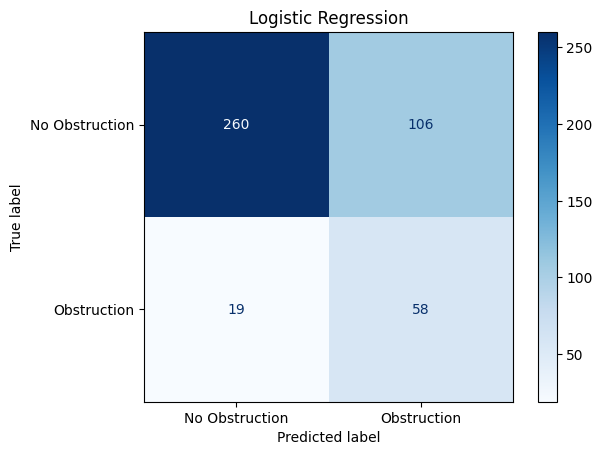


Random Forest
[[336  30]
 [ 56  21]]


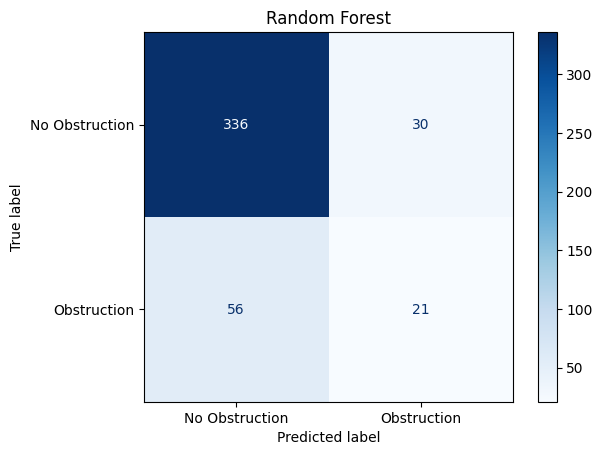


XGBoost
[[350  16]
 [ 59  18]]


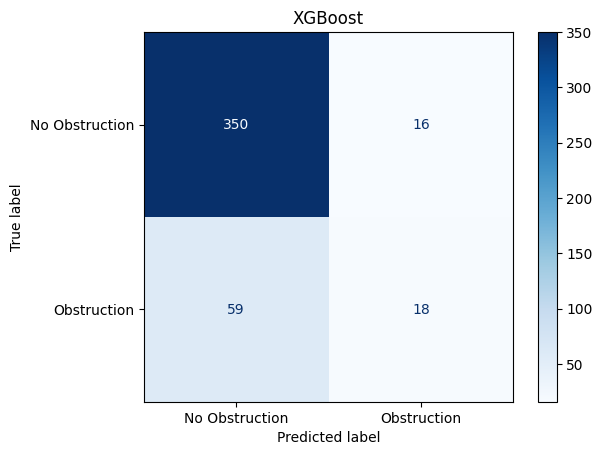

In [ ]:
# Confusion Matrices

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in models.items():
    y_pred = model.predict(X_test_processed)
    cm = confusion_matrix(y_test, y_pred)

    print(f"\n{name}")
    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Obstruction", "Obstruction"]
    ).plot(cmap="Blues")

    plt.title(name)
    plt.show()

In [ ]:
# Logistic Regression Threshold Analysis

from sklearn.metrics import classification_report

lr_model = models["Logistic Regression"]
y_prob = lr_model.predict_proba(X_test_processed)[:, 1]

for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")

    print(classification_report(
        y_test,
        y_pred_threshold,
        target_names=["No Obstruction", "Obstruction"],
        zero_division=0
    ))


Threshold: 0.3
                precision    recall  f1-score   support

No Obstruction       0.97      0.42      0.58       366
   Obstruction       0.25      0.94      0.40        77

      accuracy                           0.51       443
     macro avg       0.61      0.68      0.49       443
  weighted avg       0.84      0.51      0.55       443


Threshold: 0.4
                precision    recall  f1-score   support

No Obstruction       0.95      0.56      0.70       366
   Obstruction       0.29      0.87      0.44        77

      accuracy                           0.61       443
     macro avg       0.62      0.71      0.57       443
  weighted avg       0.84      0.61      0.66       443


Threshold: 0.5
                precision    recall  f1-score   support

No Obstruction       0.93      0.71      0.81       366
   Obstruction       0.35      0.75      0.48        77

      accuracy                           0.72       443
     macro avg       0.64      0.73      0.64   

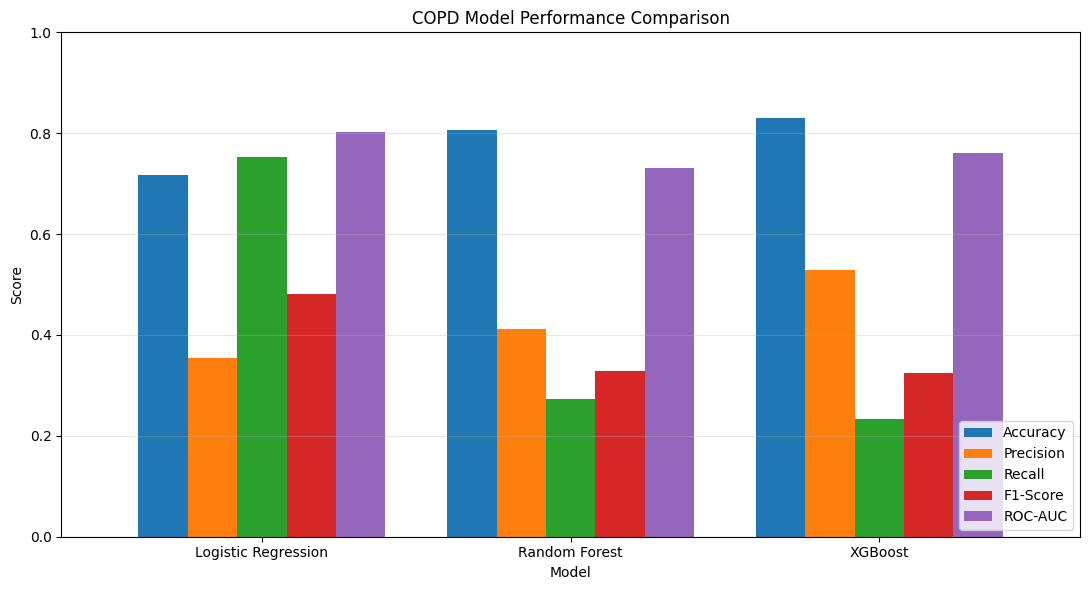

In [ ]:
# Model Performance Comparison

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("COPD Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

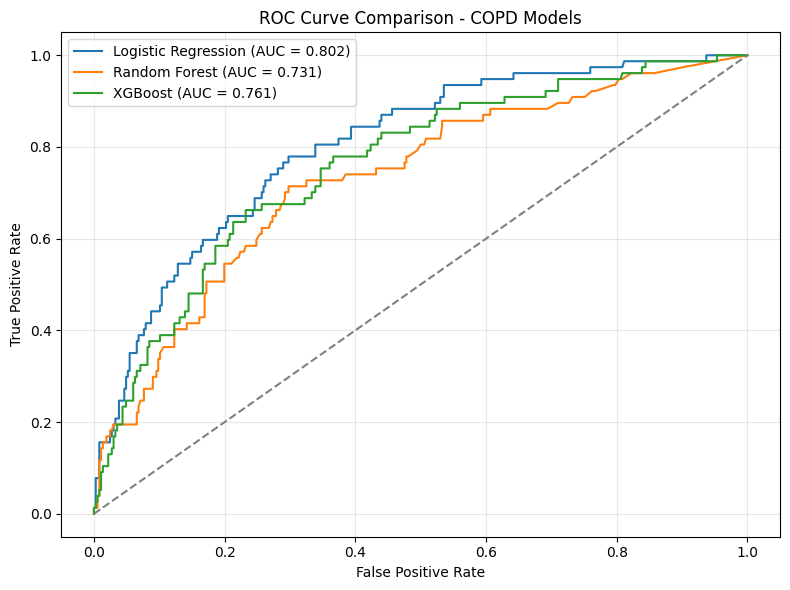

In [ ]:
# ROC Curve Comparison

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test_processed)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc(fpr, tpr):.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - COPD Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Save Final COPD Model

import joblib

final_model = models["Logistic Regression"]

joblib.dump(final_model, "copd_logistic_model.pkl")
joblib.dump(preprocessor, "copd_preprocessor.pkl")

print("COPD model saved successfully.")
print("Preprocessing pipeline saved successfully.")

COPD model saved successfully.
Preprocessing pipeline saved successfully.


## Stage 8: Model Interpretation

In [ ]:
# Logistic Regression Feature Importance

feature_names = preprocessor.get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": final_model.coef_[0]
})

coefficients["Absolute Importance"] = coefficients["Coefficient"].abs()

coefficients = coefficients.sort_values(
    "Absolute Importance", ascending=False
)

print(coefficients.head(15))

                    Feature  Coefficient  Absolute Importance
0             num__RIDAGEYR     0.786610             0.786610
4         cat__RIDRETH1_1.0    -0.721052             0.721052
29  cat__smoking_status_2.0     0.646734             0.646734
6         cat__RIDRETH1_3.0     0.642815             0.642815
27  cat__smoking_status_0.0    -0.580888             0.580888
10         cat__MCQ160G_1.0     0.425949             0.425949
18          cat__RDQ070_1.0     0.422344             0.422344
16          cat__RDQ050_1.0     0.410331             0.410331
2         cat__RIAGENDR_1.0     0.369902             0.369902
12         cat__MCQ160K_1.0     0.345783             0.345783
9          cat__MCQ160G_0.0    -0.307952             0.307952
17          cat__RDQ070_0.0    -0.304347             0.304347
15          cat__RDQ050_0.0    -0.292334             0.292334
3         cat__RIAGENDR_2.0    -0.251905             0.251905
22          cat__OCQ530_1.0     0.247135             0.247135


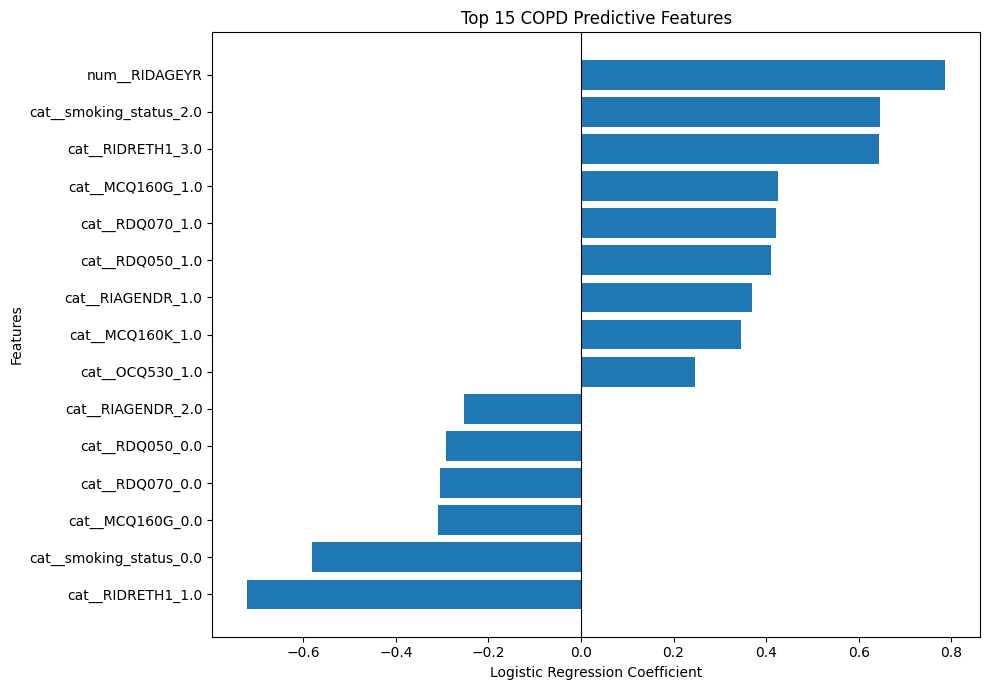

In [ ]:
# Visualize Logistic Regression Coefficients

top_features = coefficients.head(15).sort_values("Coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")
plt.title("Top 15 COPD Predictive Features")
plt.tight_layout()
plt.show()

# Stage 9: Final Results and Conclusion

## 1. Dataset Summary

- **Data source:** NHANES 2011–2012
- **Initial merged participants:** 7,495
- **Participants aged 40+:** 3,115
- **Participants with valid baseline spirometry:** 2,213
- **Selected predictor features:** 14
- **Target variable:** Baseline FEV1/FVC < 0.70

### Target Definition and Methodology

- **FEV1/FVC < 0.70:** Baseline airflow obstruction (Class 1).
- **FEV1/FVC ≥ 0.70:** No baseline airflow obstruction (Class 0).
- Participants were restricted to age 40+ with complete baseline spirometry and A/B quality grades.
- Baseline pre-bronchodilator spirometry was used to derive the target.
- Post-bronchodilator measurements were excluded from primary target construction because they were available only for a selected subgroup.
- **Important:** The target represents exploratory baseline airflow obstruction, not clinically confirmed COPD.

## 2. Model Comparison

Three classification models were trained and evaluated:

- Logistic Regression
- Random Forest
- XGBoost

### Performance Results

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 71.78% | 35.37% | 75.32% | 48.13% | 80.21% |
| Random Forest | 80.59% | 41.18% | 27.27% | 32.81% | 73.09% |
| XGBoost | 83.07% | 52.94% | 23.38% | 32.43% | 76.07% |

### Key Observations

- **Logistic Regression:**
  - Highest recall: 75.32%.
  - Highest F1-score: 48.13%.
  - Highest ROC-AUC: 80.21%.
- **Random Forest:** Achieved 80.59% accuracy but had relatively low recall.
- **XGBoost:**
  - Highest accuracy: 83.07%.
  - Highest precision: 52.94%.
  - Recall: 23.38%.

### Class Imbalance

- Class 0 (No baseline obstruction): 82.6%.
- Class 1 (Baseline obstruction): 17.4%.
- The dataset was imbalanced, so accuracy alone was not sufficient to evaluate model performance.
- Precision, recall, F1-score and ROC-AUC were also considered.
- Recall received particular attention because identifying potential airflow-obstruction cases was an important objective.

## 3. Threshold Analysis

Logistic Regression was evaluated using different probability thresholds:

| Threshold | Precision | Recall | F1-score | Accuracy |
|---|---:|---:|---:|---:|
| 0.30 | 25% | 94% | 40% | 51% |
| 0.40 | 29% | 87% | 44% | 61% |
| 0.50 | 35% | 75% | 48% | 72% |
| 0.60 | 40% | 62% | 49% | 77% |

### Key Observations

- Lower thresholds increased recall but also increased false positives.
- Higher thresholds improved precision and accuracy but reduced recall.
- The default threshold of **0.50** was retained as the primary operating point.
- At this threshold, Logistic Regression achieved 75.32% recall and 48.13% F1-score.

### Methodological Note

- Threshold comparison was performed using test-set predictions.
- Therefore, the threshold analysis should be considered exploratory.
- A separate validation set or cross-validation should be used for threshold selection in future experiments.
- The test set should ideally be reserved for final performance evaluation.

## 4. Important Features

The strongest Logistic Regression coefficients included:

- Age
- Smoking status
- Emphysema history
- Wheezing
- Persistent phlegm
- Chronic bronchitis history

### Interpretation

- Age and smoking-related features showed important associations with predicted airflow obstruction.
- Respiratory symptoms and medical history also contributed to model predictions.
- Self-reported emphysema, chronic bronchitis and respiratory symptoms may act as proxies for previously recognized respiratory disease.
- These coefficients represent predictive associations, not causal relationships or independent evidence of disease risk.

## 5. Conclusion

- Developed an exploratory machine learning pipeline for predicting baseline airflow obstruction using NHANES data.
- Integrated demographic information, smoking history, respiratory symptoms, medical history and occupational exposure features.
- Evaluated Logistic Regression, Random Forest and XGBoost.
- Logistic Regression provided the strongest recall and ROC-AUC among the evaluated models.
- The results demonstrate the potential of machine learning to identify patterns associated with baseline airflow obstruction in population-level health data.

## 6. Limitations

- The target represents baseline airflow obstruction, not clinically confirmed COPD.
- The dataset is restricted to participants aged 40+ with acceptable baseline spirometry.
- The positive class is imbalanced, which may affect model performance.
- NHANES questionnaire responses may contain self-reporting errors.
- Self-reported respiratory conditions and symptoms may overlap with the target condition and act as proxies for previously recognized disease.
- Threshold selection was explored using test-set predictions; a separate validation strategy is needed for rigorous evaluation.
- The post-bronchodilator subset is selected and cannot serve as an unbiased validation cohort.
- Independent external validation is required before any clinical application.